# 04 - 0-100 risk score, bands and the scored_customers table
`risk_score = round(calibrated P(default) x 100)`; bands 0-33 Low, 34-66 Medium, 67-100 High (PRD). Two routes are needed because 1,096 customers never applied for a loan, so they have no application features.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, json
sns.set_theme(style='whitegrid')
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40)
from src.config import PROCESSED
sc = pd.read_csv(PROCESSED / 'scored_customers.csv'); s = json.load(open('../reports/risk_score_summary.json'))
print(sc.scored_how.value_counts().to_dict()); print('rows', len(sc), '| unique customers', sc.customer_id.nunique(), '| any missing score:', sc.risk_score.isna().any())
sc[['customer_id', 'risk_score', 'risk_category', 'scored_how', 'top_risk_factors']].head(8)

{'application-based (max P over applications)': 3904, 'profile-only model (never applied)': 1096}
rows 5000 | unique customers 5000 | any missing score: False


,customer_id,risk_score,risk_category,scored_how,top_risk_factors
0,CUST100001,74,High Risk,application-based (max P over applications),debt to income ratio (+0.99); loan to income (+0.34); requested amount (+0.20)
1,CUST100002,88,High Risk,application-based (max P over applications),debt to income ratio (+0.99); credit score (+0.39); prior defaults (+0.38)
2,CUST100003,85,High Risk,application-based (max P over applications),debt to income ratio (+0.99); credit score (+0.39); loan to income (+0.38)
3,CUST100004,72,High Risk,application-based (max P over applications),debt to income ratio (+0.99); loan to income (+0.38); credit score (+0.25)
4,CUST100005,29,Low Risk,application-based (max P over applications),employment type Self-Employed (+0.25); debt to income ratio (+0.17); employment type Salaried (+0.17)
5,CUST100006,35,Medium Risk,application-based (max P over applications),debt to income ratio (+0.47); employment type Self-Employed (+0.25); employment type Salaried (+0.17)
6,CUST100007,34,Medium Risk,application-based (max P over applications),debt to income ratio (+0.61); loan to income (+0.14); loan type Education (+0.12)
7,CUST100008,17,Low Risk,profile-only model (never applied),credit score (+0.07); education Graduate (+0.07); minimum balance (+0.04)


## Are the PRD bands usable? Check against observed outcomes
Only customers who were disbursed a loan have an observed outcome (2,309). Their *cross-fitted* scores (never scored by a model that saw their own outcome) are compared with what actually happened:

In [2]:
obs = sc[sc.ever_default.notna()]
t = obs.groupby('risk_category').ever_default.agg(['mean', 'size']).reindex(['Low Risk', 'Medium Risk', 'High Risk']).round(3); print(t)
from src.models import ml_compat as ml
print('AUC of customer score vs ever-defaulted:', round(ml.roc_auc_score(obs.ever_default.astype(int), obs.default_probability), 3), '(includes extrapolated scores of rejected applications)')
print('AUC using disbursed loans only (cross-fitted):', round(s['auc_application_based_vs_ever_default_cross_fitted'], 3))

                mean  size
risk_category             
Low Risk       0.222  1243
Medium Risk    0.399   784
High Risk      0.507   282
AUC of customer score vs ever-defaulted: 0.664 (includes extrapolated scores of rejected applications)
AUC using disbursed loans only (cross-fitted): 0.716


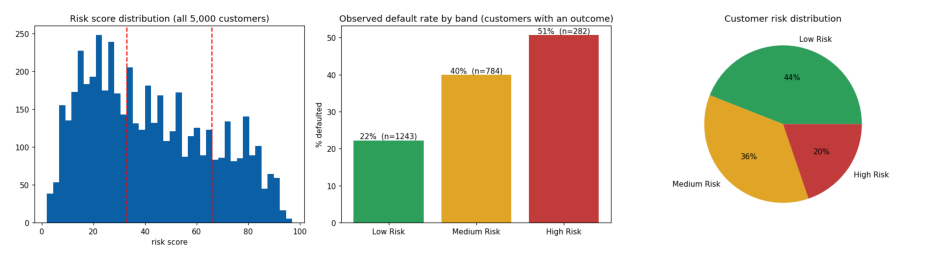

In [3]:
import matplotlib.image as mpimg
fig, ax = plt.subplots(figsize=(17, 4.6)); ax.imshow(mpimg.imread('../images/risk_scoring.png')); ax.axis('off'); plt.show()

**Result:** the PRD default cut-offs separate outcomes (High ~50% vs Low ~22% observed default), so they were kept - no re-tuning. The High band holds ~20% of customers; whether to decline, price or review them is a business decision this analysis cannot make.

## Two caveats that matter
1. **Selection bias.** For rejected/under-review applications the outcome was never observed; their probabilities (mean ~0.53 vs 0.24 for disbursed) are *extrapolations* of a model trained on safer loans (median DTI 0.71 vs 2.39). Customer scores that rest on such applications should be read as 'high-risk profile', not as a measured default probability.
2. **'Never applied' customers** are scored by a weaker profile-only model (loan-grain AUC ~0.66).

In [4]:
print(sc.groupby('scored_how').agg(customers=('customer_id', 'size'), mean_p=('default_probability', 'mean'), share_high=('risk_category', lambda x: (x == 'High Risk').mean())).round(3))
sa = pd.read_csv(PROCESSED / 'scored_applications.csv'); print(sa.groupby('scored_how').default_probability.describe().round(3))

                                             customers  mean_p  share_high
scored_how                                                                
application-based (max P over applications)       3904   0.451       0.253
profile-only model (never applied)                1096   0.300       0.000
                                                     count   mean    std    min    25%    50%    75%    max
scored_how                                                                                                 
cross-fitted (loan was disbursed)                   3403.0  0.236  0.153  0.015  0.123  0.198  0.309  0.898
extrapolated (loan not disbursed - outcome neve...  4097.0  0.526  0.225  0.016  0.347  0.537  0.716  0.967


## Explainability: every score has ranked reasons (occlusion method)
SHAP is not installed here; for each customer we replace one feature at a time with the population median and record the change in the model's log-odds.

In [5]:
w = sc[sc.risk_category == 'High Risk'].sort_values('risk_score', ascending=False).head(6)[['customer_id', 'risk_score', 'credit_score', 'top_risk_factors']]; w.to_string(index=False)

'customer_id  risk_score  credit_score                                                                     top_risk_factors\n CUST102747          97           531 debt to income ratio (+0.99); 30-day late payments (+0.42); requested amount (+0.39)\n CUST104013          95           569   debt to income ratio (+0.99); 30-day late payments (+0.42); prior defaults (+0.38)\n CUST104504          95           530         debt to income ratio (+0.99); prior defaults (+0.38); loan to income (+0.38)\n CUST100205          95           407         debt to income ratio (+0.99); credit score (+0.39); requested amount (+0.39)\n CUST103038          95           502           debt to income ratio (+0.99); credit score (+0.39); prior defaults (+0.38)\n CUST101549          94           526         debt to income ratio (+0.99); prior defaults (+0.38); loan to income (+0.38)'

In [6]:
print(sc.top_risk_factors.str.split(';').str[0].str.replace(r' \(.*', '', regex=True).value_counts().head(6))

top_risk_factors
debt to income ratio             2625
credit score                      511
30-day late payments              477
employment type Self-Employed     330
employment type Salaried          230
credit inquiries                  164
Name: count, dtype: int64


## scored_customers table
The PostgreSQL DDL is in `sql/scored_customers.sql` (FK to customers, range checks); `src/export.py` writes the exact-column CSV for `\copy`. Loaded into SQLite here and used by the dashboard queries D1-D8:

In [7]:
from src import data_load as dl
t_, _ = dl.clean(); con = dl.build_sqlite(tables=t_); dl.add_scores(con)
print(pd.read_sql_query('SELECT risk_category, COUNT(*) n, ROUND(AVG(risk_score),1) avg_score FROM scored_customers GROUP BY 1 ORDER BY MIN(risk_score)', con))
print(dl.run_dashboard_queries(con)['D8']['df'].head(5).to_string(index=False))

  risk_category     n  avg_score
0      Low Risk  2201       19.9
1   Medium Risk  1811       48.6
2     High Risk   988       78.4
customer_id       city       state employment_type  credit_score  risk_score risk_category                                                                     top_risk_factors
 CUST102747    Kolkata West Bengal   Self-Employed           531          97     High Risk debt to income ratio (+0.99); 30-day late payments (+0.42); requested amount (+0.39)
 CUST100205      Delhi       Delhi      Unemployed           407          95     High Risk         debt to income ratio (+0.99); credit score (+0.39); requested amount (+0.39)
 CUST103038  Hyderabad   Telangana         Retired           502          95     High Risk           debt to income ratio (+0.99); credit score (+0.39); prior defaults (+0.38)
 CUST104013 Chandigarh  Chandigarh        Salaried           569          95     High Risk   debt to income ratio (+0.99); 30-day late payments (+0.42); prior defau